# 01 · EDA and Model Comparison: NYC Yellow Taxi Trip Duration (January 2025)

This notebook covers the exploration behind the decisions in `src/` and the model results
tracked in MLflow:

1. **Inspect** the raw January 2025 data.
2. **Define the target** (`duration`) and justify the cleaning rules.
3. **Explore** what drives trip duration.
4. **Check for leakage**: why fare, tip and total are not used as features.
5. **Split**: train on Jan 1–24, validate on Jan 25–31.
6. **Compare models** logged in MLflow: baseline, Optuna-tuned, and full-data.
7. **Old vs new cleaning**: the 1–60 min model against the 1–180 min model on the same trips.

It reuses `src/data.py` and `src/features.py`, so the notebook and the training code apply
exactly the same cleaning and features.

In [1]:
import os
import sys
from pathlib import Path

# Run from the repo root so `src` imports and relative data paths work.
if Path.cwd().name == "notebooks":
    os.chdir("..")
sys.path.insert(0, str(Path.cwd()))
os.environ["MLFLOW_DISABLE_AGENT_HINT"] = "1"

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.data import (DATA_PATH, MAX_DISTANCE, MAX_DURATION, MAX_SPEED, MIN_DURATION, MIN_SPEED,
                      RAW_COLUMNS, SPLIT_DATE, clean, load_raw, split)
from src.features import FEATURES

plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.float_format", "{:,.2f}".format)

## 1. Load and inspect the raw data

In [2]:
if not DATA_PATH.exists():
    load_raw()  # downloads the parquet file on first run
raw = pd.read_parquet(DATA_PATH)
print(f"{len(raw):,} trips x {raw.shape[1]} columns")
raw.head()

3,475,226 trips x 20 columns


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee
0,1,2025-01-01 00:18:38,2025-01-01 00:26:59,1.00,1.60,1.00,N,229,237,1,10.00,3.50,0.50,3.00,0.00,1.00,18.00,2.50,0.00,0.00
1,1,2025-01-01 00:32:40,2025-01-01 00:35:13,1.00,0.50,1.00,N,236,237,1,5.10,3.50,0.50,2.02,0.00,1.00,12.12,2.50,0.00,0.00
2,1,2025-01-01 00:44:04,2025-01-01 00:46:01,1.00,0.60,1.00,N,141,141,1,5.10,3.50,0.50,2.00,0.00,1.00,12.10,2.50,0.00,0.00
3,2,2025-01-01 00:14:27,2025-01-01 00:20:01,3.00,0.52,1.00,N,244,244,2,7.20,1.00,0.50,0.00,0.00,1.00,9.70,0.00,0.00,0.00
4,2,2025-01-01 00:21:34,2025-01-01 00:25:06,3.00,0.66,1.00,N,244,116,2,5.80,1.00,0.50,0.00,0.00,1.00,8.30,0.00,0.00,0.00


In [3]:
summary = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "missing": raw.isna().sum(),
    "missing_%": raw.isna().mean() * 100,
})
summary

,dtype,missing,missing_%
VendorID,int32,0,0.00
tpep_pickup_datetime,datetime64[us],0,0.00
tpep_dropoff_datetime,datetime64[us],0,0.00
passenger_count,float64,540149,15.54
trip_distance,float64,0,0.00
RatecodeID,float64,540149,15.54
store_and_fwd_flag,str,540149,15.54
PULocationID,int32,0,0.00
DOLocationID,int32,0,0.00
payment_type,int64,0,0.00


About **15.5%** of rows are missing `passenger_count`, `RatecodeID`, `store_and_fwd_flag`,
`congestion_surcharge` and `Airport_fee`, all in the same rows. Of these, only
`passenger_count` is a model feature, and it is filled with 1 (the most common value) in
`src/features.py`.

## 2. Define the target: `duration` in minutes

In [4]:
raw["duration"] = (raw["tpep_dropoff_datetime"] - raw["tpep_pickup_datetime"]).dt.total_seconds() / 60
raw["duration"].describe(percentiles=[0.01, 0.05, 0.5, 0.95, 0.99])

count   3,475,226.00
mean           15.02
std            38.71
min       -51,472.32
1%              0.67
5%              3.37
50%            11.70
95%            36.20
99%            58.92
max         5,626.32
Name: duration, dtype: float64

In [5]:
d = raw["duration"]
pd.Series({
    "negative duration": (d < 0).sum(),
    "under 1 min": (d < MIN_DURATION).sum(),
    "60-180 min": d.between(60, 180, inclusive="right").sum(),
    f"over {MAX_DURATION} min": (d > MAX_DURATION).sum(),
    "over 24 hours": (d > 24 * 60).sum(),
    "share within 1-60 min": d.between(MIN_DURATION, 60).mean(),
    f"share within {MIN_DURATION}-{MAX_DURATION} min": d.between(MIN_DURATION, MAX_DURATION).mean(),
}).to_frame("count / share")

,count / share
negative duration,124.00
under 1 min,"40,111.00"
60-180 min,"30,490.00"
over 180 min,"1,377.00"
over 24 hours,20.00
share within 1-60 min,0.98
share within 1-180 min,0.99


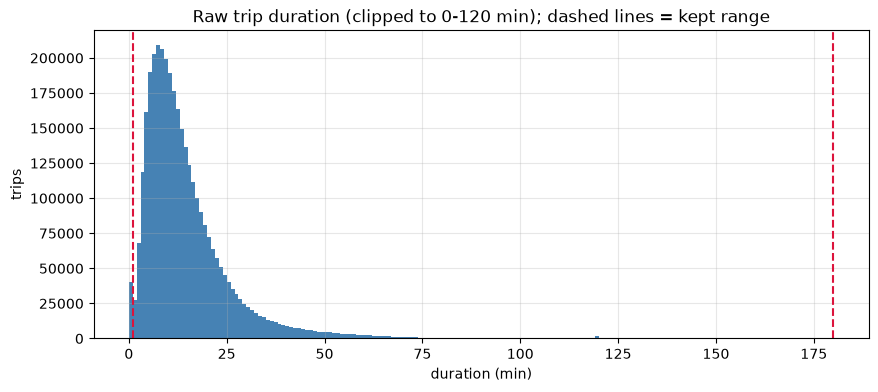

In [6]:
fig, ax = plt.subplots()
ax.hist(d.clip(0, 120), bins=120, color="steelblue")
for x in (MIN_DURATION, MAX_DURATION):
    ax.axvline(x, color="crimson", ls="--")
ax.set(title="Raw trip duration (clipped to 0-120 min); dashed lines = kept range",
       xlabel="duration (min)", ylabel="trips")
plt.show()

The data contains impossible durations: negative values (clock or recording errors) and
trips lasting days (meters left running).

- **Range kept: 1–180 minutes.** The first version kept only 1–60 minutes (97.9% of
  trips). That silently removed about 30,000 real long trips, mostly airport runs. The
  model then could not predict anything over an hour, and it underestimated long trips
  (review finding 2.4).
- Trips under 1 minute are mostly cancelled or test trips, so they are still dropped.

In [7]:
dist = raw["trip_distance"]
pd.Series({
    "zero distance": (dist == 0).sum(),
    f"over {MAX_DISTANCE} miles": (dist > MAX_DISTANCE).sum(),
    "max distance": dist.max(),
    "pickups outside January": (~raw["tpep_pickup_datetime"].between("2025-01-01", "2025-02-01", inclusive="left")).sum(),
}).to_frame("value")

,value
zero distance,"90,893.00"
over 100 miles,162.00
max distance,"276,423.57"
pickups outside January,22.00


### Speed check and refund pairs

Widening the range to 180 minutes needs a second check, so that broken records (for
example a meter left running in a parked cab) don't slip in. A trip's average speed has to
be between **1 and 65 mph**. Below 1 mph is slower than gridlock; above 65 mph is
impossible on NYC roads.

In [8]:
w = raw[raw["duration"].between(MIN_DURATION, MAX_DURATION) & raw["trip_distance"].between(0, MAX_DISTANCE, inclusive="right")]
mph = w["trip_distance"] / (w["duration"] / 60)
print(f"trips {MIN_DURATION}-{MAX_DURATION} min: {len(w):,}")
print(f"  slower than {MIN_SPEED} mph: {(mph < MIN_SPEED).sum():,}   faster than {MAX_SPEED} mph: {(mph > MAX_SPEED).sum():,}")
print(f"  median speed of trips over 60 min: {mph[w['duration'] > 60].median():.1f} mph (so most long trips are real)")

trips 1-180 min: 3,369,231
  slower than 1 mph: 12,657   faster than 65 mph: 252
  median speed of trips over 60 min: 14.8 mph (so most long trips are real)


Some trips appear **twice**. These are not exact duplicates (no two rows match on all 20
columns). They are **refund or reversal pairs**: the same trip recorded a second time with
the fare negated, mostly with payment types 3 (no charge) and 4 (dispute). Time, zones,
distance and passengers are identical in both rows, so `clean()` keeps one row per trip.

In [9]:
pairs = raw[raw.duplicated(subset=RAW_COLUMNS, keep=False)]
print(f"rows sharing all 6 model columns with another row: {len(pairs):,}  (extra copies: {raw.duplicated(subset=RAW_COLUMNS).sum():,})")
print(f"rows identical on all 20 columns: {raw.drop(columns='duration').duplicated().sum():,}")
pairs.sort_values(["tpep_pickup_datetime", "PULocationID"])[
    ["tpep_pickup_datetime", "PULocationID", "DOLocationID", "trip_distance", "fare_amount", "total_amount", "payment_type"]].head(6)

rows sharing all 6 model columns with another row: 105,064  (extra copies: 52,533)


rows identical on all 20 columns: 0


,tpep_pickup_datetime,PULocationID,DOLocationID,trip_distance,fare_amount,total_amount,payment_type
5515,2025-01-01 00:00:07,148,45,0.93,-7.90,-12.90,3
5516,2025-01-01 00:00:07,148,45,0.93,7.90,12.90,3
4531,2025-01-01 00:01:19,164,164,0.00,0.00,-2.50,2
4532,2025-01-01 00:01:19,164,164,0.00,0.00,2.50,2
17,2025-01-01 00:01:41,79,107,0.71,-7.20,-8.54,2
18,2025-01-01 00:01:41,79,107,0.71,7.20,12.20,2


Next, apply the same cleaning as training (`src.data.clean`):

In [10]:
df = clean(raw)
print(f"kept {len(df):,} of {len(raw):,} trips ({len(df) / len(raw):.1%})")
df["duration"].describe()

kept 3,310,437 of 3,475,226 trips (95.3%)


count   3,310,437.00
mean           14.72
std            11.26
min             1.00
25%             7.40
50%            11.77
75%            18.37
max           179.97
Name: duration, dtype: float64

## 3. What drives trip duration?

The plots use a 200k-row sample to keep them fast.

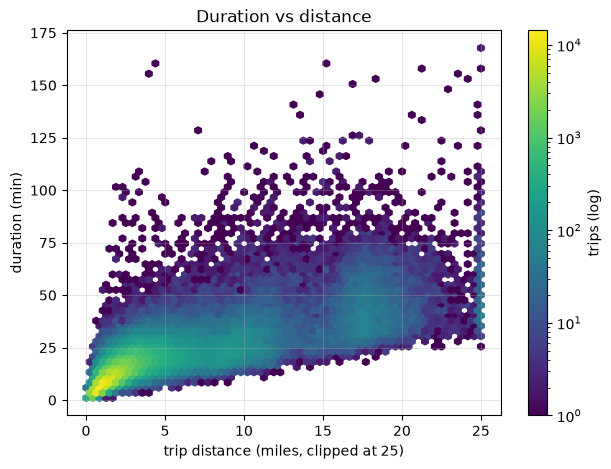

Pearson correlation, distance vs duration: 0.804


In [11]:
sample = df.sample(200_000, random_state=42)

fig, ax = plt.subplots(figsize=(7, 5))
hb = ax.hexbin(sample["trip_distance"].clip(upper=25), sample["duration"], gridsize=60, bins="log", cmap="viridis")
fig.colorbar(hb, label="trips (log)")
ax.set(title="Duration vs distance", xlabel="trip distance (miles, clipped at 25)", ylabel="duration (min)")
plt.show()
print("Pearson correlation, distance vs duration:", round(df["trip_distance"].corr(df["duration"]), 3))

Distance is by far the strongest signal. The vertical spread at any given distance comes
from traffic, which depends on **when** and **where** the trip happens:

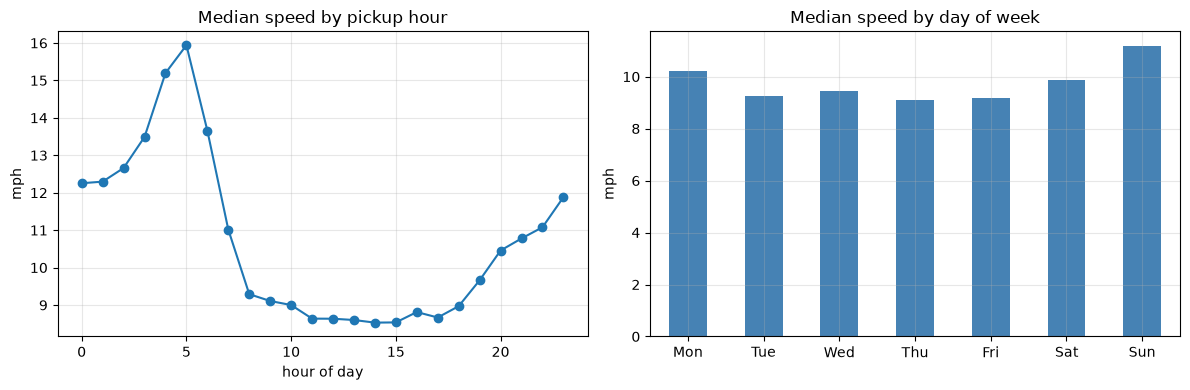

In [12]:
pickup = df["tpep_pickup_datetime"]
speed = df["trip_distance"] / (df["duration"] / 60)  # mph

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
speed.groupby(pickup.dt.hour).median().plot(ax=axes[0], marker="o")
axes[0].set(title="Median speed by pickup hour", xlabel="hour of day", ylabel="mph")
dow = speed.groupby(pickup.dt.day_of_week).median()
dow.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
dow.plot.bar(ax=axes[1], color="steelblue", rot=0)
axes[1].set(title="Median speed by day of week", ylabel="mph")
plt.tight_layout()
plt.show()

Speeds drop during the day and at the evening rush, and recover overnight. Weekends are
faster than weekdays. This is why `pickup_hour` and `pickup_dow` are features.

**Monday is unexpectedly fast.** The next cell breaks it down by date:

In [13]:
mondays = df[pickup.dt.day_of_week == 0]
mon_speed = speed[mondays.index].groupby(mondays["tpep_pickup_datetime"].dt.date).median()
print(mon_speed.round(2).to_string())
print("Tue-Fri median speed:", round(speed[pickup.dt.day_of_week.between(1, 4)].median(), 2))

tpep_pickup_datetime
2025-01-06    9.86
2025-01-13    9.80
2025-01-20   11.58
2025-01-27    9.63
Tue-Fri median speed: 9.24


**Monday, Jan 20 was Martin Luther King Jr. Day.** Holiday traffic was much lighter
(about 11.6 mph vs 9.6–9.8 mph on the other Mondays), which pulls up the Monday average.
Day of week alone cannot tell a holiday from a normal Monday, so a **holiday flag** is a
concrete feature to add next. Ordinary Mondays are still slightly faster than
Tuesday–Friday.

In [14]:
top = df["PULocationID"].value_counts().head(10).index
by_zone = (df[df["PULocationID"].isin(top)]
           .assign(speed=speed)
           .groupby("PULocationID")
           .agg(trips=("duration", "size"), median_duration=("duration", "median"),
                median_distance=("trip_distance", "median"), median_speed=("speed", "median"))
           .sort_values("trips", ascending=False))
by_zone

,trips,median_duration,median_distance,median_speed
PULocationID,,,,
161,163277,11.83,1.51,8.13
237,158993,8.97,1.21,8.55
236,151189,9.32,1.40,9.00
132,134450,37.98,17.30,25.19
230,120424,12.07,1.56,8.71
186,114910,12.77,1.50,8.24
162,113499,11.53,1.51,8.54
142,107342,10.15,1.60,9.70
239,93540,9.83,1.60,9.72


The busiest pickup zones differ a lot in typical distance and speed. Airport zones
(132 = JFK, 138 = LaGuardia) have long, fast trips, while Midtown and Upper East Side
zones have short, slow ones. This is why the zone IDs are features.

In [15]:
pc = df["passenger_count"].fillna(1).clip(upper=6)
df.groupby(pc)["duration"].agg(["size", "median"]).rename_axis("passenger_count")

,size,median
passenger_count,,
0.00,23523,10.55
1.00,2722706,11.72
2.00,392817,11.98
3.00,87645,12.07
4.00,54455,13.08
5.00,17493,10.70
6.00,11798,10.77


Passenger count barely changes duration. It is kept because it is cheap, but the model
gives it almost no weight (see the feature importances below).

## 4. Leakage check: why fare, tip and total are excluded

These columns correlate strongly with duration, but they are **computed from the finished
trip**: the metered fare includes time charges. A prediction API is called *before* the
trip, so these values don't exist yet when the prediction is needed.

In [16]:
cols = ["trip_distance", "fare_amount", "total_amount", "tip_amount", "tolls_amount"]
# Re-load with the money columns; clean() applies the same filters as training.
cleaned_full = clean(pd.read_parquet(DATA_PATH, columns=[
    "tpep_pickup_datetime", "tpep_dropoff_datetime", "PULocationID", "DOLocationID",
    "trip_distance", "passenger_count", *cols[1:]]))
corr = pd.DataFrame({
    "pearson": cleaned_full[cols + ["duration"]].corr()["duration"],
    "spearman (rank)": cleaned_full[cols + ["duration"]].corr(method="spearman")["duration"],
}).drop("duration").sort_values("spearman (rank)", ascending=False)
corr

,pearson,spearman (rank)
fare_amount,0.03,0.87
trip_distance,0.80,0.86
total_amount,0.03,0.83
tolls_amount,0.43,0.34
tip_amount,0.44,0.30


In [17]:
fare = cleaned_full["fare_amount"]
print(f"negative fares: {(fare < 0).sum():,}   max fare: ${fare.max():,.0f}")

negative fares: 124,296   max fare: $863,372


The two correlation measures disagree, and the reason matters:

- **Pearson** says fare barely relates to duration (about 0.02). This is an artefact of
  bad data. More than 126k negative fares (refunds and voids) and one fare of over
  $860,000 dominate a measure based on squared deviations.
- **Spearman**, which uses ranks and so isn't thrown off by extreme values, shows that
  `fare_amount` tracks duration **more closely than trip distance does** (about 0.87 vs
  0.85). That makes sense, because NYC meters charge for time spent in slow traffic.

So fare would be a very strong feature offline, but it is only known once the trip is
over. Using it would give a great validation RMSE and a model that cannot be used before
the trip starts.

**Features used:** `PULocationID`, `DOLocationID`, `trip_distance`, `passenger_count`, `pickup_hour`, `pickup_dow`.

## 5. Train / validation split (by time)

In [18]:
train_df, val_df = split(df)
pd.DataFrame({
    "trips": [len(train_df), len(val_df)],
    "from": [train_df.tpep_pickup_datetime.min(), val_df.tpep_pickup_datetime.min()],
    "to": [train_df.tpep_pickup_datetime.max(), val_df.tpep_pickup_datetime.max()],
    "mean duration": [train_df.duration.mean(), val_df.duration.mean()],
}, index=["train", "validation"])

,trips,from,to,mean duration
train,2517854,2025-01-01,2025-01-24 23:59:59,14.67
validation,792583,2025-01-25,2025-01-31 23:59:59,14.85


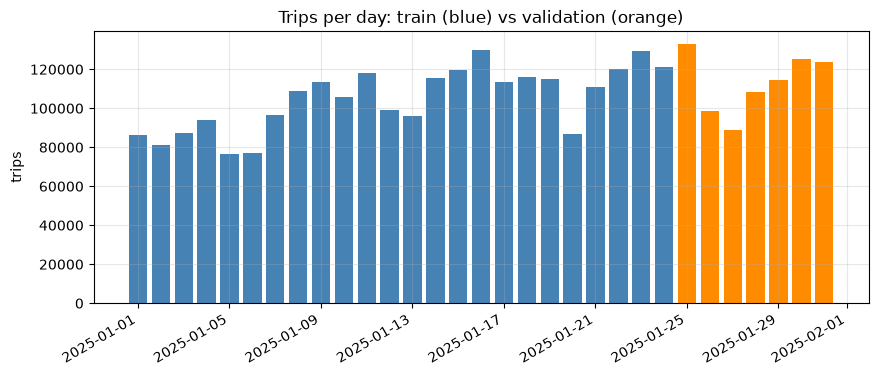

In [19]:
daily = df.groupby(df["tpep_pickup_datetime"].dt.date).size()
fig, ax = plt.subplots()
ax.bar(daily.index, daily.values, color=["steelblue" if pd.Timestamp(x) < SPLIT_DATE else "darkorange" for x in daily.index])
ax.set(title="Trips per day: train (blue) vs validation (orange)", ylabel="trips")
fig.autofmt_xdate()
plt.show()

Splitting by date simulates the real task, which is predicting trips that happen
*after* the training data. Validation also includes a full weekend, so it isn't skewed
towards weekdays.

## 6. Model comparison (from MLflow)

All runs are logged to the local `mlflow.db` (experiment `nyc-taxi-duration`). The cells
below read the top-level runs. The Optuna search's 25 individual trials are stored as
nested child runs and are excluded here.

In [20]:
import mlflow

from src.paths import MLFLOW_DB

mlflow.set_tracking_uri(f"sqlite:///{MLFLOW_DB}")
runs = mlflow.search_runs(experiment_names=["nyc-taxi-duration"],
                          filter_string="attributes.status = 'FINISHED'", order_by=["start_time DESC"])
runs = runs[runs["tags.mlflow.parentRunId"].isna()]
# Runs from before the review fixes don't log their cleaning rules: those used 1-60 min trips.
runs["cleaning"] = np.where(runs["params.max_duration"].fillna("60") == "60", "v1: 1-60 min", "v2: 1-180 min + fixes")
cols = {"cleaning": "cleaning", "tags.mlflow.runName": "run", "params.train_rows": "train_rows",
        "metrics.rmse_train": "rmse_train", "metrics.rmse_val": "rmse_val",
        "metrics.rmse_val_le60min": "rmse_le60", "metrics.rmse_val_gt60min": "rmse_gt60",
        "metrics.model_size_mb": "size_mb"}
table = runs[list(cols)].rename(columns=cols).sort_values(["cleaning", "rmse_val"], ascending=[False, False]).reset_index(drop=True)
table

,cleaning,run,train_rows,rmse_train,rmse_val,rmse_le60,rmse_gt60,size_mb
0,v2: 1-180 min + fixes,rf-baseline,500000,3.97,4.95,4.11,28.17,254.47
1,v2: 1-180 min + fixes,rf-optuna,500000,3.41,4.86,4.01,27.97,"1,683.40"
2,v2: 1-180 min + fixes,rf-fulldata,2517854,4.12,4.79,3.96,27.22,740.33
3,v1: 1-60 min,rf-baseline,500000,3.36,4.10,NaN,NaN,NaN
4,v1: 1-60 min,rf-optuna,500000,2.87,4.02,NaN,NaN,"1,681.36"
5,v1: 1-60 min,rf-baseline-fulldata,2540706,3.50,3.96,NaN,NaN,729.07


v1 and v2 RMSEs **cannot be compared directly**: v2's validation set also contains trips of
60–180 minutes, which are much harder to predict. Section 7 compares both on the same
trips. The chart below shows the v2 runs only.

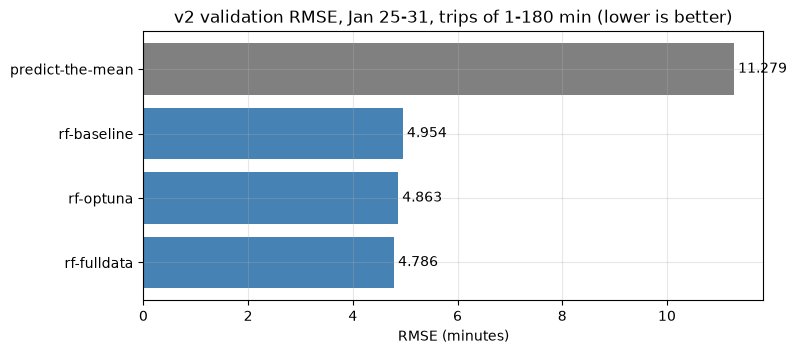

In [21]:
v2 = runs[runs["cleaning"].str.startswith("v2")]
mean_rmse = v2["metrics.rmse_val_mean_baseline"].dropna().iloc[0]
v2_table = table[table["cleaning"].str.startswith("v2")]
plot_df = pd.concat([pd.DataFrame({"run": ["predict-the-mean"], "rmse_val": [mean_rmse]}), v2_table[["run", "rmse_val"]]])

fig, ax = plt.subplots(figsize=(8, 3.5))
bars = ax.barh(plot_df["run"], plot_df["rmse_val"], color=["grey"] + ["steelblue"] * (len(plot_df) - 1))
ax.bar_label(bars, fmt="%.3f", padding=3)
ax.invert_yaxis()
ax.set(title="v2 validation RMSE, Jan 25-31, trips of 1-180 min (lower is better)", xlabel="RMSE (minutes)")
plt.show()

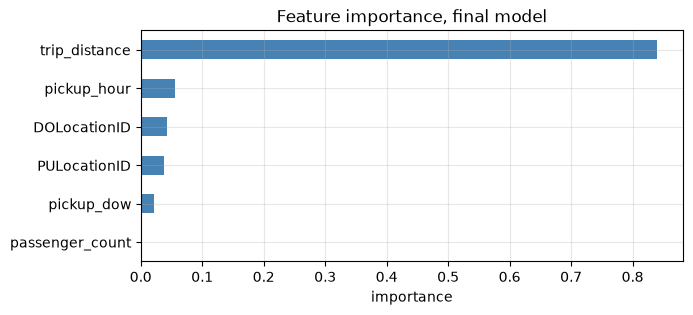

In [22]:
final = v2[v2["tags.mlflow.runName"] == "rf-fulldata"].iloc[0]  # latest served model
imp = pd.Series(mlflow.artifacts.load_dict(f"runs:/{final.run_id}/feature_importances.json")).sort_values()
ax = imp.plot.barh(color="steelblue", figsize=(7, 3))
ax.set(title="Feature importance, final model", xlabel="importance")
plt.show()

Optuna best params: {'min_samples_leaf': '3', 'max_features': '0.5', 'max_depth': '26', 'n_estimators': '150'}


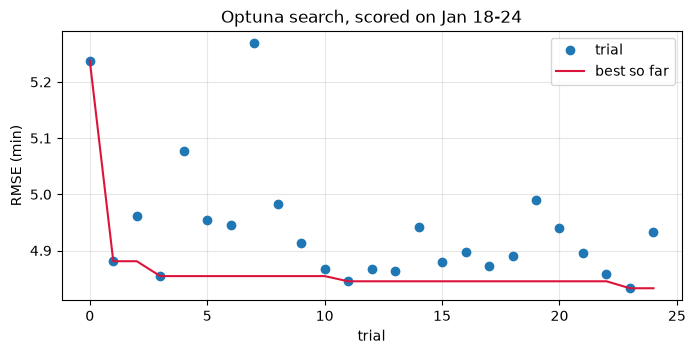

In [23]:
tuned = v2[v2["tags.mlflow.runName"] == "rf-optuna"].iloc[0]
print("Optuna best params:", {k.removeprefix("params.best_"): tuned[k] for k in runs if k.startswith("params.best_") and pd.notna(tuned[k])})

trials = mlflow.search_runs(experiment_names=["nyc-taxi-duration"],
                            filter_string=f"tags.mlflow.parentRunId = '{tuned.run_id}'")
fig, ax = plt.subplots(figsize=(8, 3.5))
order = trials.sort_values("start_time")
ax.plot(range(len(order)), order["metrics.rmse_tune_val"], "o", label="trial")
ax.plot(range(len(order)), order["metrics.rmse_tune_val"].cummin(), "-", color="crimson", label="best so far")
ax.set(title="Optuna search, scored on Jan 18-24", xlabel="trial", ylabel="RMSE (min)")
ax.legend()
plt.show()

## 7. Old vs new cleaning, on the same trips

Both served models are scored on the **same v2 validation week** (Jan 25–31, 1–180 min
trips): v1 was trained on 1–60 min trips, v2 on 1–180 min trips with the speed check and
refund pairs removed. The table gives overall RMSE, RMSE for trips up to and over
60 minutes, and RMSE by distance range.

In [24]:
from src.evaluate import segment_metrics
from src.model import load_model
from src.paths import ARTIFACTS_DIR
from src.features import prepare_features

_, val_v2 = split(clean(load_raw()))
Xv, yv = prepare_features(val_v2), val_v2["duration"].to_numpy()
res = {}
for name, f in [("v1: 1-60 min", "model_v1_60min.skops"), ("v2: 1-180 min + fixes", "model.skops")]:
    path = ARTIFACTS_DIR / f
    if not path.exists():
        print(f"skipping {name}: {path.name} not found")
        continue
    p = load_model(path).predict(Xv)
    res[name] = {**segment_metrics(yv, p, Xv["trip_distance"]), "max prediction": p.max(), "predictions > 60 min": int((p > 60).sum())}
print(f"{len(yv):,} validation trips, {(yv > 60).sum():,} of them over 60 min")
pd.DataFrame(res)

792,583 validation trips, 7,847 of them over 60 min


,v1: 1-60 min,v2: 1-180 min + fixes
rmse_val,5.13,4.79
bias_val,-0.71,-0.49
rmse_val_le60min,3.91,3.96
rmse_val_gt60min,33.65,27.22
bias_val_gt60min,-28.69,-20.56
rmse_val_dist_0_2mi,2.69,2.69
rmse_val_dist_2_5mi,4.65,4.66
rmse_val_dist_5_10mi,7.95,7.74
rmse_val_dist_10_20mi,12.53,10.84
rmse_val_dist_20_100mi,18.11,13.43


**What changed:**

- **Better overall:** RMSE on all validation trips fell from about 5.13 to **4.79**.
- **Much better on long trips:** RMSE on trips over 60 min fell from about 33.7 to 27.2,
  and on 20+ mile trips from about 18.1 to 13.4. The model can now predict over an hour
  (up to about 125 min).
- **Small cost on short trips:** RMSE on trips up to 60 min rose from 3.91 to 3.97, about
  1.5%.

**Still a limitation:** trips over an hour are still **underestimated by about 20 minutes on
average**. Distance, zone and time of day can't see what makes those trips slow, such as
crashes, closures or weather. Better features are the next lever, not more data cleaning.

## Conclusions

- **Cleaning (v2):**
  - Keep trips of 1–180 minutes travelling at 1–65 mph.
  - Count refund and reversal pairs once.
  - This retains about 95% of the data and keeps real long trips that v1 dropped.
- **Signal:** distance dominates feature importance. Hour, day of week and zones capture
  traffic and add the rest.
- **Leakage:** fare and total amounts are excluded because they are only known after the
  trip ends.
- **Models (v2 validation week, 1–180 min trips):**
  - The served model (baseline settings, all 2.52M training trips) reaches **RMSE
    4.786 min**, against 11.28 for always predicting the average.
  - **Optuna tuning (4.863) still helped less than using all the data:** it beat the
    500k-row baseline (4.954), but its model file is about 7× larger.
- **v1 vs v2 on the same trips:** v2 is better overall (5.13 → 4.79) and much better on
  long trips, for a 1.5% cost on short trips. Long trips are still underestimated by about
  20 min.
- **Next steps:** better features (historical duration for each zone pair, a holiday flag
  as the MLK Day check shows, weather), gradient boosting, and predicting
  `log(duration)`.